# ClaimGuard AI — Week 1 EDA: Vehicle Insurance Claim Fraud Detection

**Dataset:** `fraud_oracle.csv` (Kaggle: shivamb/vehicle-claim-fraud-detection)
**Target:** `FraudFound_P` (binary flag as provided by the dataset author)
**Purpose:** validate schema/quality, understand the target definition, surface leakage risk, and produce the data dictionary inputs for the Week 1 exit gate.

**Caveat:** `FraudFound_P` reflects whatever the original claims process flagged in 1994–1996 and is **not** a verified legal determination of fraud. All findings below describe *this historical, labeled dataset*, not current claims behavior.

## 1. Load and basic shape

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

DATA_PATH = '../data/raw/fraud_oracle.csv'
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()


Shape: (15420, 33)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,21,Policy Holder,Sport - Liability,Sport,more than 69000,0,1,12,300,1,more than 30,more than 30,none,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,34,Policy Holder,Sport - Collision,Sport,more than 69000,0,2,15,400,4,more than 30,more than 30,none,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,47,Policy Holder,Sport - Collision,Sport,more than 69000,0,3,7,400,3,more than 30,more than 30,1,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,65,Third Party,Sedan - Liability,Sport,20000 to 29000,0,4,4,400,2,more than 30,more than 30,1,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,27,Third Party,Sport - Collision,Sport,more than 69000,0,5,3,400,1,more than 30,more than 30,none,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [2]:
df.dtypes


Month                   object
WeekOfMonth              int64
DayOfWeek               object
Make                    object
AccidentArea            object
DayOfWeekClaimed        object
MonthClaimed            object
WeekOfMonthClaimed       int64
Sex                     object
MaritalStatus           object
Age                      int64
Fault                   object
PolicyType              object
VehicleCategory         object
VehiclePrice            object
FraudFound_P             int64
PolicyNumber             int64
RepNumber                int64
Deductible               int64
DriverRating             int64
Days_Policy_Accident    object
Days_Policy_Claim       object
PastNumberOfClaims      object
AgeOfVehicle            object
AgeOfPolicyHolder       object
PoliceReportFiled       object
WitnessPresent          object
AgentType               object
NumberOfSuppliments     object
AddressChange_Claim     object
NumberOfCars            object
Year                     int64
BasePoli

## 2. Data quality checks

### 2a. Nulls vs. sentinel values

A naive `.isna().sum()` reports **zero** missing values — but this dataset encodes some missingness as sentinel strings/numbers rather than true nulls. We check both.

In [3]:
print('True NaN cells:', df.isna().sum().sum())
print('Full-row duplicates:', df.duplicated().sum())


True NaN cells: 0
Full-row duplicates: 0


In [4]:
# Sentinel check: '0' appears as a placeholder in day/month-claimed fields
for col in ['DayOfWeekClaimed', 'MonthClaimed']:
    n = (df[col] == '0').sum()
    print(f"{col}: {n} row(s) with sentinel '0'")


DayOfWeekClaimed: 1 row(s) with sentinel '0'
MonthClaimed: 1 row(s) with sentinel '0'


In [5]:
# Age == 0 is implausible for a policyholder age — investigate
print('Age == 0 count:', (df['Age'] == 0).sum())
print()
print('AgeOfPolicyHolder bucket for Age==0 rows:')
print(df.loc[df['Age'] == 0, 'AgeOfPolicyHolder'].value_counts())


Age == 0 count: 320

AgeOfPolicyHolder bucket for Age==0 rows:
AgeOfPolicyHolder
16 to 17    320
Name: count, dtype: int64


**Finding:** all 320 rows with `Age == 0` fall in the `AgeOfPolicyHolder == '16 to 17'` bucket. This is almost certainly a data-entry/encoding quirk (age not captured for minors) rather than a real age of zero. Treat `Age == 0` as a quality flag, not a literal value — prefer the bucketed `AgeOfPolicyHolder` field, or impute/flag `Age` for modeling.

**Action for modeling:** keep both columns but document that `Age` has a known sentinel at 0; consider a binary `age_unknown` flag instead of feeding 0 directly into a linear model (0 would otherwise look like the youngest possible policyholder, which is misleading).

In [6]:
# Identifier columns that are not legitimate predictors
print('PolicyNumber unique:', df['PolicyNumber'].nunique(), 'of', len(df), '-> pure row identifier, exclude from features')
print('RepNumber unique:', df['RepNumber'].nunique(), '-> claims rep ID; exclude or treat as high-cardinality categorical with care')


PolicyNumber unique: 15420 of 15420 -> pure row identifier, exclude from features
RepNumber unique: 16 -> claims rep ID; exclude or treat as high-cardinality categorical with care


## 3. Target variable: `FraudFound_P`

FraudFound_P
0    14497
1      923
Name: count, dtype: int64

FraudFound_P
0    0.940143
1    0.059857
Name: proportion, dtype: float64


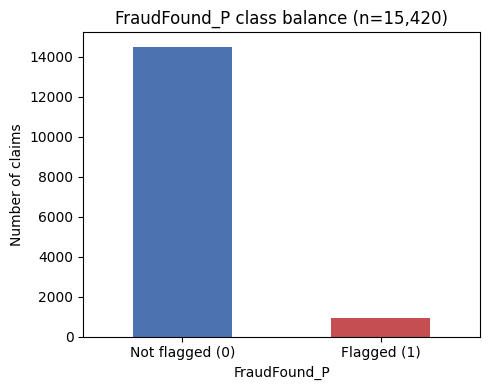

In [7]:
counts = df['FraudFound_P'].value_counts()
rates = df['FraudFound_P'].value_counts(normalize=True)
print(counts)
print()
print(rates)

fig, ax = plt.subplots(figsize=(5, 4))
counts.sort_index().plot(kind='bar', ax=ax, color=['#4C72B0', '#C44E52'])
ax.set_xticklabels(['Not flagged (0)', 'Flagged (1)'], rotation=0)
ax.set_ylabel('Number of claims')
ax.set_title('FraudFound_P class balance (n=15,420)')
plt.tight_layout()
plt.savefig('../reports/figures/target_balance.png', dpi=150)
plt.show()


**Finding:** 923 of 15,420 claims (**5.99%**) carry `FraudFound_P == 1`. This is a strongly imbalanced binary target — plain accuracy will be a meaningless metric; plan on PR-AUC, recall/precision@K, and class-weighted or resampled training strictly inside CV folds.

## 4. Dataset era and scope

Year values: [1994, 1995, 1996]


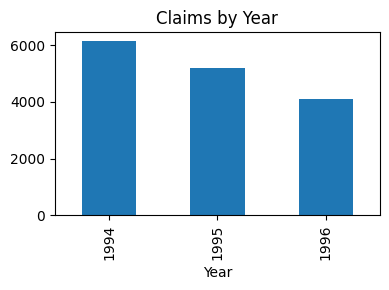

In [8]:
print('Year values:', sorted(df['Year'].unique()))
df['Year'].value_counts().sort_index().plot(kind='bar', figsize=(4,3), title='Claims by Year')
plt.tight_layout()
plt.savefig('../reports/figures/claims_by_year.png', dpi=150)
plt.show()


**Finding:** all claims are from **1994–1996**. This is a 30-year-old dataset — results describe historical patterns only and must not be framed as reflecting current fraud behavior, pricing, or demographics.

## 5. Categorical field cardinality and sentinel scan

In [9]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
summary = []
for c in cat_cols:
    vals = df[c].unique()
    summary.append({'column': c, 'n_unique': len(vals), 'sample_values': list(vals[:6])})
pd.DataFrame(summary)


,column,n_unique,sample_values
0,Month,12,"[Dec, Jan, Oct, Jun, Feb, Nov]"
1,DayOfWeek,7,"[Wednesday, Friday, Saturday, Monday, Tuesday,..."
2,Make,19,"[Honda, Toyota, Ford, Mazda, Chevrolet, Pontiac]"
3,AccidentArea,2,"[Urban, Rural]"
4,DayOfWeekClaimed,8,"[Tuesday, Monday, Thursday, Friday, Wednesday,..."
5,MonthClaimed,13,"[Jan, Nov, Jul, Feb, Mar, Dec]"
6,Sex,2,"[Female, Male]"
7,MaritalStatus,4,"[Single, Married, Widow, Divorced]"
8,Fault,2,"[Policy Holder, Third Party]"
9,PolicyType,9,"[Sport - Liability, Sport - Collision, Sedan -..."


## 6. Fraud rate by key operational fields

In [10]:
def fraud_rate_by(col, min_n=20):
    g = df.groupby(col)['FraudFound_P'].agg(['mean', 'count'])
    g = g[g['count'] >= min_n].sort_values('mean', ascending=False)
    return g

for col in ['Fault', 'VehicleCategory', 'PolicyType', 'BasePolicy', 'AccidentArea', 'PastNumberOfClaims', 'AddressChange_Claim']:
    print(f'--- {col} ---')
    print(fraud_rate_by(col))
    print()


--- Fault ---
                   mean  count
Fault                         
Policy Holder  0.078896  11230
Third Party    0.008831   4190

--- VehicleCategory ---
                     mean  count
VehicleCategory                 
Utility          0.112532    391
Sedan            0.082205   9671
Sport            0.015677   5358

--- PolicyType ---
                          mean  count
PolicyType                           
Sport - Collision     0.137931    348
Utility - All Perils  0.120588    340
Sedan - All Perils    0.100563   4087
Utility - Collision   0.100000     30
Sedan - Collision     0.068768   5584
Sedan - Liability     0.007219   4987
Sport - All Perils    0.000000     22
Utility - Liability   0.000000     21

--- BasePolicy ---
                mean  count
BasePolicy                 
All Perils  0.101596   4449
Collision   0.072962   5962
Liability   0.007187   5009

--- AccidentArea ---
                  mean  count
AccidentArea                 
Rural         0.083229   1598


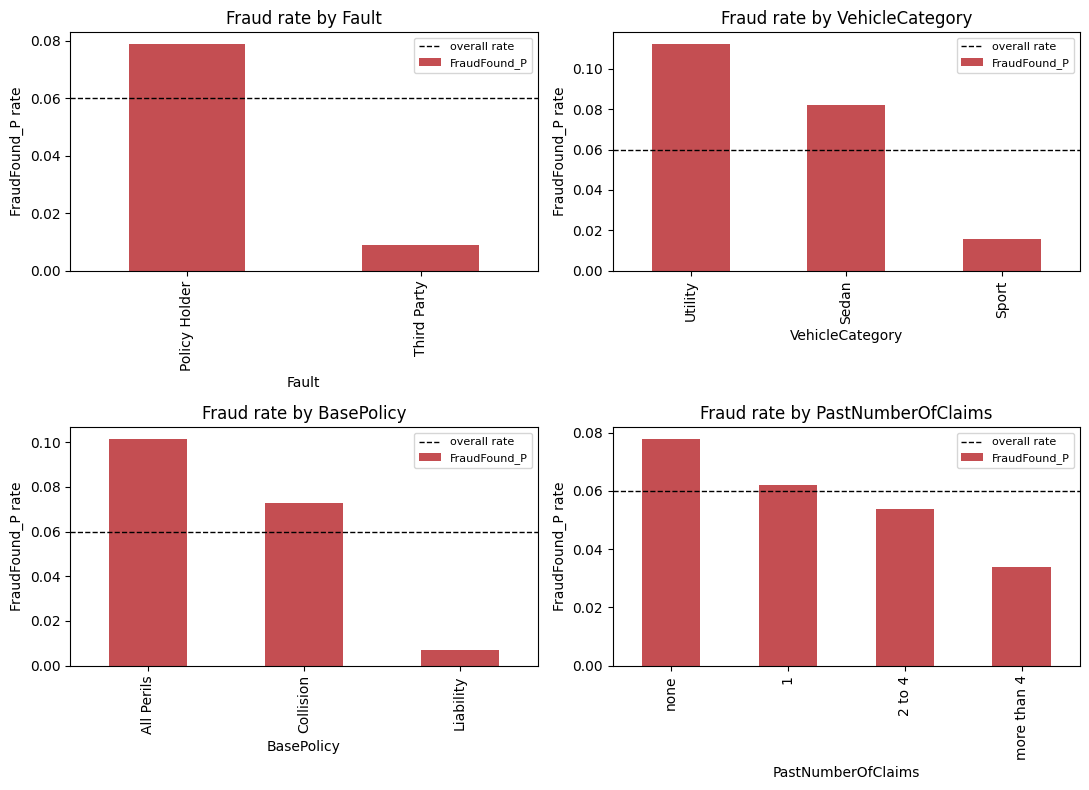

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), ['Fault', 'VehicleCategory', 'BasePolicy', 'PastNumberOfClaims']):
    g = df.groupby(col)['FraudFound_P'].mean().sort_values(ascending=False)
    g.plot(kind='bar', ax=ax, color='#C44E52')
    ax.axhline(df['FraudFound_P'].mean(), color='black', linestyle='--', linewidth=1, label='overall rate')
    ax.set_title(f'Fraud rate by {col}')
    ax.set_ylabel('FraudFound_P rate')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('../reports/figures/fraud_rate_by_field.png', dpi=150)
plt.show()


**Observations (descriptive only — not causal, not evidence of actual fraud):**
- Claims where `Fault == 'Policy Holder'` show a markedly higher flag rate than `Third Party` fault claims in this dataset.
- `Sedan`/`Sport` vehicle categories and certain `BasePolicy` types show different flag rates — plausible confounding with claim size and policy type, not a standalone signal.
- These are *associations within this historical, imbalanced, dataset-defined label* — they describe what this dataset's labeling process correlated with, not general fraud risk factors.

## 7. Leakage audit — would this field be known when an analyst first scores the claim?

| Field | Available at scoring time? | Notes |
|---|---|---|
| `PolicyNumber`, `RepNumber` | N/A | Identifiers — exclude from model features |
| `Month`, `WeekOfMonth`, `DayOfWeek`, `Make`, `AccidentArea`, `Sex`, `MaritalStatus`, `Age`, `PolicyType`, `VehicleCategory`, `VehiclePrice`, `Deductible`, `DriverRating`, `AgeOfVehicle`, `AgeOfPolicyHolder`, `AgentType`, `NumberOfCars`, `Year`, `BasePolicy` | Yes | Policy/incident attributes known at or before filing |
| `DayOfWeekClaimed`, `MonthClaimed`, `WeekOfMonthClaimed`, `Days_Policy_Accident`, `Days_Policy_Claim` | Yes | Known once claim is filed (reporting delay) — legitimate scoring-time signal |
| `Fault` | Caution | Fault determination may finalize after some investigation; treat as an early-but-not-day-zero signal, document in model card |
| `PastNumberOfClaims`, `NumberOfSuppliments`, `AddressChange_Claim` | Yes | Known from policy/claim history at filing |
| `PoliceReportFiled`, `WitnessPresent` | Yes, if captured at intake | Typically captured during initial claim intake |
| `FraudFound_P` | Target | The outcome being predicted — never a feature |

**No field was found that is determined only *after* a fraud conclusion** (e.g., there is no "investigation outcome" or "recovery amount" column), so the main leakage risk here is **identifier leakage** (`PolicyNumber`, `RepNumber` memorizing row identity) rather than outcome leakage. Both will be excluded from the training feature set.

## 8. Week 1 summary and caveats

1. **Shape:** 15,420 rows, 33 columns, 0 true NaNs, 0 duplicate rows — but missingness is partly encoded as sentinels (`'0'` strings, `Age == 0`), not nulls.
2. **Target:** `FraudFound_P` is 5.99% positive — significant class imbalance; use PR-AUC/precision@K/recall@K, not accuracy.
3. **Era:** claims are from 1994–1996; treat all findings as historical pattern description, not current risk.
4. **Identifiers:** `PolicyNumber` (unique per row) and `RepNumber` must be excluded or handled carefully — not legitimate predictive signal.
5. **Known sentinel:** `Age == 0` always co-occurs with `AgeOfPolicyHolder == '16 to 17'`; needs explicit handling (flag or impute) rather than being fed as a literal numeric age.
6. **Leakage:** no post-outcome fields found; `Fault` flagged for caution/documentation since full fault determination may not be instantaneous.
7. **Associations found** (`Fault`, vehicle/policy type, past-claims count) are descriptive only, per dataset limitations in the project plan — never framed as fraud evidence.

**Exit gate status:** every included feature's availability-at-scoring-time has been reviewed (Section 7). Ready to proceed to Week 2 (train/val/test split design and baseline modeling), pending final feature-list sign-off in the data dictionary.